# 06 · Eletrodo 2 · MCF10A em três condições de meio

Comparamos 12 aplicações de MCF10A no E02, quatro por condição:

- **Controle 1:** MCF10A com meio de MCF10A.
- **Controle 2:** MCF10A com meio puro de HCC.
- **Condicionado HCC:** MCF10A com meio condicionado de HCC.

Cada ponto do PCA representa uma aplicação física. Usamos os espectros históricos do E02 e calculamos a diferença entre a fase média da aplicação e a fase média do PBS de mesmo número, na convenção −Phase dos arquivos. Cada espectro médio reúne as três leituras técnicas da aplicação ou do PBS, e a diferença é resumida em sete bandas de 0,1 Hz a 1 MHz.

A leitura P05_eletrodo2(1).txt do arquivo bruto teve módulo mediano de 1,45 Ω e foi excluída conforme o registro do pacote. As outras três leituras de P05 foram usadas para o pareamento com A05.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RAIZ = Path.cwd()
PACOTE = RAIZ / 'TCC_EIS_Modelos_Basicos'
assert (PACOTE / 'dados').is_dir(), 'Abra o notebook na pasta raiz do projeto.'
sys.path.insert(0, str(PACOTE))
from eis_utils import read_all, get_e02_pair_table, band_average

ARQUIVO = PACOTE / 'dados' / 'Medicoes_EIS_Por_Dispositivo_ATUALIZADO_E02.zip'
PASTA_FIGURAS = RAIZ / 'imagens_prontas_eletrodo2'
PASTA_FIGURAS.mkdir(exist_ok=True)
plt.rcParams.update({
    'font.family': 'Times New Roman', 'pdf.fonttype': 42,
    'figure.dpi': 120, 'font.size': 11, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'legend.fontsize': 11, 'legend.title_fontsize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'axes.edgecolor': '#ABB5BD', 'grid.color': '#D8DEE3', 'grid.alpha': .7,
    'figure.constrained_layout.use': True,
})
CONDICOES = {
    'Controle1': ('Controle 1', 'Controle 1 · meio de MCF10A', '#0079B7', 's'),
    'Controle2': ('Controle 2', 'Controle 2 · meio puro de HCC', '#276445', '^'),
    'cond.HCC': ('Condicionado HCC', 'Meio condicionado de HCC', '#BF5A3C', 'o'),
}
TEXTO = '#202934'

aplicacoes = read_all(ARQUIVO, drop_known_short=True)
assert aplicacoes.attrs['excluded_files'] == ['E02/P05_eletrodo2(1).txt']
e2 = get_e02_pair_table(aplicacoes).sort_values('order').reset_index(drop=True)
assert e2.order.tolist() == list(range(1, 13))
assert e2.condition.value_counts().to_dict() == dict.fromkeys(CONDICOES, 4)
assert e2[['scans_ves', 'scans_pbs']].eq(3).all().all()
bordas = [.1, 1, 10, 100, 1_000, 10_000, 100_000, 1_000_000]
X = np.array([
    [band_average(r.f, r.phase_delta, lo, hi) for lo, hi in zip(bordas, bordas[1:])]
    for r in e2.itertuples(index=False)
])
assert X.shape == (12, 7) and np.isfinite(X).all()
y = e2.condition.map({k: v[0] for k, v in CONDICOES.items()}).to_numpy()
ids = [f'A{n:02d}' for n in e2.order]
display(pd.DataFrame({'Aplicação': ids, 'Condição': y, 'PBS': [f'P{n:02d}' for n in e2.order]}))

,Aplicação,Condição,PBS
0,A01,Controle 1,P01
1,A02,Controle 2,P02
2,A03,Condicionado HCC,P03
3,A04,Controle 2,P04
4,A05,Condicionado HCC,P05
5,A06,Controle 1,P06
6,A07,Condicionado HCC,P07
7,A08,Controle 1,P08
8,A09,Controle 2,P09
9,A10,Controle 1,P10


## PCA exploratório

Padronizamos as sete bandas nas 12 aplicações e projetamos os dados nos dois primeiros componentes. As condições são usadas para colorir e identificar os pontos após a projeção. Os identificadores A01 a A12 permitem acompanhar a ordem de aplicação.

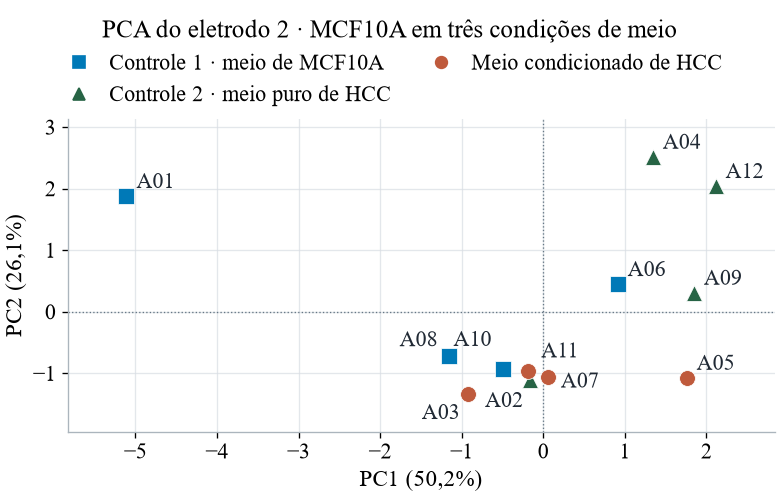

Variância explicada pelos dois componentes: 76.3%.


In [2]:
pca = PCA(n_components=2)
scores = pca.fit_transform(StandardScaler().fit_transform(X))
with plt.rc_context({'font.size': 13, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'axes.labelsize': 14, 'axes.titlesize': 15, 'figure.labelsize': 14,
                     'legend.fontsize': 13, 'legend.title_fontsize': 15}):
    fig, ax = plt.subplots(figsize=(16.5 / 2.54, 10.5 / 2.54))
    for rotulo, legenda, cor, marcador in CONDICOES.values():
        mask = y == rotulo
        ax.scatter(scores[mask, 0], scores[mask, 1], s=90, color=cor, marker=marcador,
                   linewidths=.45, edgecolors='white', zorder=3)
    ajustes = {
        'A02': (-4, -13), 'A03': (-5, -12), 'A07': (8, -3),
        'A08': (-7, 9), 'A10': (-7, 17), 'A11': (8, 11),
    }
    for id_gota, (pc1, pc2) in zip(ids, scores):
        dx, dy = ajustes.get(id_gota, (6, 8))
        ax.annotate(id_gota, (pc1, pc2), xytext=(dx, dy), textcoords='offset points',
                    ha='right' if dx < 0 else 'left', va='center', color=TEXTO)
    ax.axhline(0, color='#667785', ls=':', lw=.8)
    ax.axvline(0, color='#667785', ls=':', lw=.8)
    v1, v2 = [f'{100*p:.1f}'.replace('.', ',') for p in pca.explained_variance_ratio_]
    ax.set(xlabel=f'PC1 ({v1}%)', ylabel=f'PC2 ({v2}%)')
    ax.grid()
    ax.margins(x=.10, y=.16)
    handles = [
        Line2D([], [], ls='', marker=marcador, color=cor, label=legenda, markersize=7)
        for _, legenda, cor, marcador in CONDICOES.values()
    ]
    fig.legend(handles=handles, loc='outside upper center', ncol=2, frameon=False,
               handletextpad=.4, columnspacing=1.3,
               title='PCA do eletrodo 2 · MCF10A em três condições de meio')
    fig.savefig(PASTA_FIGURAS / 'eletrodo2_pca_tres_condicoes.pdf')
    plt.show()
print(f'Variância explicada pelos dois componentes: {100*pca.explained_variance_ratio_.sum():.1f}%.')

## PCA exploratório em três dimensões

Projetamos os mesmos sete atributos padronizados nos três primeiros componentes. Cada ponto é uma das 12 aplicações físicas, identificada pela ordem de aplicação. Os percentuais nos eixos indicam a variância explicada por cada componente.

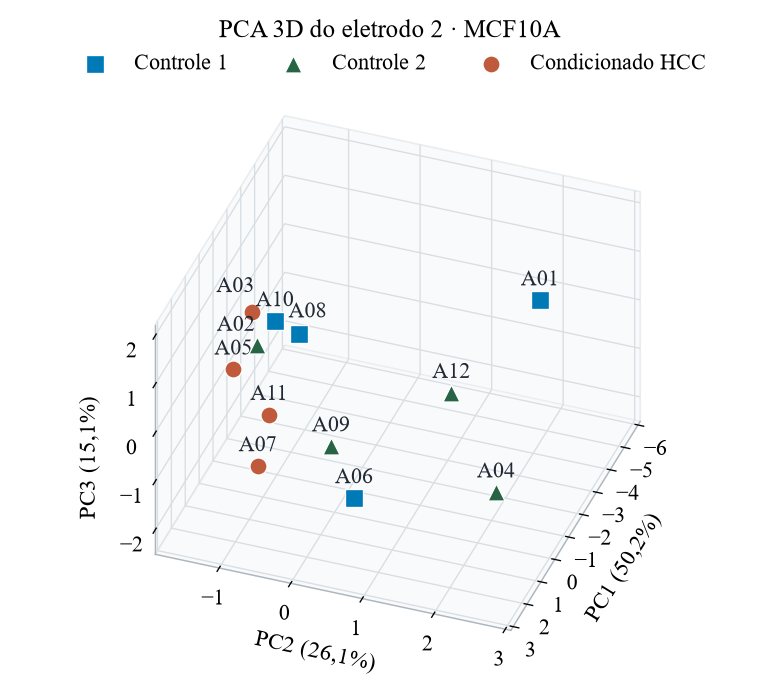

Variância explicada pelos três componentes: 91,4%.


In [ ]:
pca_3d = PCA(n_components=3)
scores_3d = pca_3d.fit_transform(StandardScaler().fit_transform(X))
variancia_3d = 100 * pca_3d.explained_variance_ratio_

from mpl_toolkits.mplot3d import proj3d

with plt.rc_context({'axes.labelsize': 14, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'legend.fontsize': 13, 'legend.title_fontsize': 15}):
    fig = plt.figure(figsize=(16.5 / 2.54, 14.4 / 2.54))
    ax = fig.add_subplot(projection='3d', proj_type='ortho')
    for rotulo, _, cor, marcador in CONDICOES.values():
        pontos = scores_3d[y == rotulo]
        ax.scatter(*pontos.T, s=105, color=cor, marker=marcador, depthshade=False,
                   linewidths=.8, edgecolors='white', label=rotulo)
    rotulos_eixos = [
        f'PC{i} ({variancia:.1f}%)'.replace('.', ',')
        for i, variancia in enumerate(variancia_3d, start=1)
    ]
    ax.set(xlabel=rotulos_eixos[0], ylabel=rotulos_eixos[1], zlabel=rotulos_eixos[2])
    ax.tick_params(labelsize=13, pad=1)
    ax.margins(x=.12, y=.12, z=.16)
    for eixo in (ax.xaxis, ax.yaxis, ax.zaxis):
        eixo.pane.set_facecolor('#F4F6F8')
        eixo.pane.set_edgecolor('#D8DEE3')
    fig.legend(loc='outside upper center', ncol=3, frameon=False,
               title='PCA 3D do eletrodo 2 · MCF10A')
    ax.view_init(elev=36, azim=20)
    fig.canvas.draw()
    deslocamentos = {'A02': (-13, 6), 'A03': (-10, 9), 'A08': (5, 7)}
    for identificador, ponto in zip(ids, scores_3d):
        x, y_projetado, _ = proj3d.proj_transform(*ponto, ax.get_proj())
        ax.annotate(identificador, (x, y_projetado), xytext=deslocamentos.get(identificador, (0, 6)),
                    textcoords='offset points', ha='center', va='bottom',
                    fontsize=13, color=TEXTO)
    fig.savefig(PASTA_FIGURAS / 'eletrodo2_pca_3d_tres_condicoes.pdf')
    plt.show()

total_3d = f'{variancia_3d.sum():.1f}'.replace('.', ',')
print(f'Variância explicada pelos três componentes: {total_3d}%.')

## Classificação exploratória com PCA + LDA

Formamos quatro trios a partir da ordem de aplicação. Cada trio consecutivo contém uma gota de cada condição. Em cada rodada, um trio inteiro fica fora do treino. A padronização, o PCA com dois componentes e a LDA são ajustados nas nove gotas restantes. Cada uma das 12 gotas recebe uma previsão. Esse desenho avalia a discriminação dentro da sequência do E02. Uma avaliação da transferência para novos lotes exigiria novas preparações ou eletrodos.

,Aplicação,Trio excluído,Registrada,Prevista
0,A01,1,Controle 1,Controle 1
1,A02,1,Controle 2,Condicionado HCC
2,A03,1,Condicionado HCC,Controle 1
3,A04,2,Controle 2,Controle 2
4,A05,2,Condicionado HCC,Controle 2
5,A06,2,Controle 1,Controle 2
6,A07,3,Condicionado HCC,Condicionado HCC
7,A08,3,Controle 1,Condicionado HCC
8,A09,3,Controle 2,Controle 2
9,A10,4,Controle 1,Condicionado HCC


6/12 acertos (50.0%)


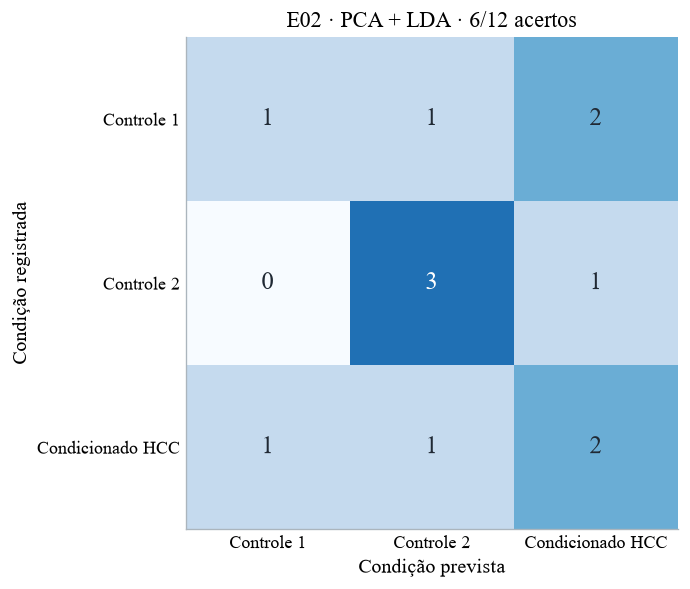

In [3]:
trios = (e2.order.to_numpy() - 1) // 3 + 1
assert pd.crosstab(trios, y).eq(1).all().all()
divisor = LeaveOneGroupOut()
pipeline = make_pipeline(StandardScaler(), PCA(n_components=2), LinearDiscriminantAnalysis())
pred = cross_val_predict(pipeline, X, y, groups=trios, cv=divisor)
rotulos = [v[0] for v in CONDICOES.values()]
matriz = confusion_matrix(y, pred, labels=rotulos)
acertos = np.count_nonzero(y == pred)
assert matriz.sum() == len(y) and matriz.trace() == acertos
display(pd.DataFrame({'Aplicação': ids, 'Trio excluído': trios, 'Registrada': y, 'Prevista': pred}))
print(f'{acertos}/{len(y)} acertos ({acertos/len(y):.1%})')

fig, ax = plt.subplots(figsize=(5.7, 4.8))
ax.imshow(matriz, cmap='Blues', vmin=0, vmax=4)
for (i, j), n in np.ndenumerate(matriz):
    ax.text(j, i, str(n), ha='center', va='center', fontsize=15, color='white' if n >= 3 else TEXTO)
ax.set_xticks(range(len(rotulos)), rotulos)
ax.set_yticks(range(len(rotulos)), rotulos)
ax.tick_params(length=0)
ax.set(xlabel='Condição prevista', ylabel='Condição registrada',
       title=f'E02 · PCA + LDA · {acertos}/{len(y)} acertos')
fig.savefig(PASTA_FIGURAS / 'eletrodo2_pca_lda_matriz_confusao.pdf', bbox_inches='tight')
plt.show()

## Leitura para a discussão

Os dois primeiros componentes explicam 76,3% da variância, com sobreposição entre as condições. A classificação fora do trio acertou 6/12 aplicações: 1/4 no controle 1, 3/4 no controle 2 e 2/4 no condicionado HCC. A separação observada é parcial e descreve este conjunto de aplicações no E02.